# Section 1: Introduction

This notebook addresses **R004** with a physical-first thermal model for the HeatSync heating window. The main model is a calibrated 2R2C grey-box circuit over a room-level time series, followed by a small residual corrector.

The 2R2C analogy represents the space as two thermal states: indoor air temperature and a slower wall/building-mass temperature. The two resistances model heat-transfer bottlenecks between indoor air, wall mass, and outdoor ambient air; the two capacitances model how much thermal energy is required to change indoor-air and wall temperatures. Calibrating these values with positivity bounds keeps the fitted model physically plausible while still using measured data to identify effective parameters.

The neural component is deliberately a residual corrector. It does not replace the physical model or use a simplified one-state physics residual. Instead, it learns remaining residual structure after the 2R2C simulation has already captured the room thermal dynamics.

# Section 2: Room-Level Physical Input Selection

The processed HeatSync data has one row per device and timestamp, but the modeled thermal state is room temperature. We therefore aggregate to one room-level row per timestamp before calibration.

Inputs used by the physical model:

- `T_in`: mean observed indoor air temperature across reporting devices.
- `T_out`: mean outside temperature across reporting devices.
- `Q_electric_kw`: current electrical power draw summed over all room devices.
- `Q_heat_kw`: delivered-heat proxy used by the 2R2C equation. In this notebook it is `Q_electric_kw * ASSUMED_HEATING_COP`; the default COP is 1.0 because the dataset does not include a COP curve by operating condition.
- `electricity_kwh`: current 15-minute interval electricity spent, derived from summed electrical power.
- `cumulative_electricity_kwh`: cumulative measured electricity spent over the modeled window.

This fixes the single-device mismatch: room temperature is now modeled against the combined electrical input from all four heat pump devices serving the room. The heat term is still an effective proxy, not audited useful thermal output.

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from torch import nn

warnings.filterwarnings("ignore")
np.random.seed(42)
torch.manual_seed(42)

# Required by the task plan; useful when launched from backend/notebooks.
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

# Robust path support for programmatic execution from the repository root.
backend_path = os.path.abspath("backend")
if os.path.isdir(backend_path) and backend_path not in sys.path:
    sys.path.append(backend_path)

from notebooks.utils import build_room_physical_model_frame, load_processed  # noqa: E402

DT_SECONDS = 900.0
SECONDS_PER_HOUR = 3_600.0
ASSUMED_HEATING_COP = 1.0
MIN_CALIBRATION_ROWS = 10

heating_df = load_processed("heating")
model_df = (
    build_room_physical_model_frame(
        heating_df,
        dt_seconds=DT_SECONDS,
        cop=ASSUMED_HEATING_COP,
    )
    .iloc[:300]
    .copy()
)

if len(model_df) < MIN_CALIBRATION_ROWS:
    raise ValueError(
        f"Need at least {MIN_CALIBRATION_ROWS} complete room-level rows for 2R2C calibration."
    )

T_in = model_df["T_in"].to_numpy(dtype=float)
T_out = model_df["T_out"].to_numpy(dtype=float)
Q_heat = model_df["Q_heat_kw"].to_numpy(dtype=float)
Q_electric = model_df["Q_electric_kw"].to_numpy(dtype=float)
dt = DT_SECONDS
dt_hours = dt / SECONDS_PER_HOUR

min_devices = model_df["device_count"].min()
max_devices = model_df["device_count"].max()

print(f"Room-level timestamps: {len(model_df)}")
print(f"Devices per timestamp: {min_devices:.0f}-{max_devices:.0f}")
print(f"Assumed heating COP for Q proxy: {ASSUMED_HEATING_COP:.2f}")
print(f"Total measured electricity: {model_df['electricity_kwh'].sum():.2f} kWh")
display(model_df.head())

Room-level timestamps: 300
Devices per timestamp: 4-4
Assumed heating COP for Q proxy: 1.00
Total measured electricity: 1924.66 kWh


,T_in,T_out,Q_electric_kw,device_count,target_temp,occupancy_flag,is_heating_required,is_cooling_required,status_is_compressor_active,status_is_defrost_active,hour_of_day,day_of_week,is_weekend,Q_heat_kw,electricity_kwh,cumulative_electricity_kwh
timestamp,,,,,,,,,,,,,,,,
2026-03-30 00:00:00,18.625000,1.252500,4.703333,4,11.0,0,0,0,0.0,0.0,0,0,0,4.703333,1.175833,1.175833
2026-03-30 00:15:00,18.424000,1.540000,4.696667,4,11.0,0,0,0,0.0,0.0,0,0,0,4.696667,1.174167,2.350000
2026-03-30 00:30:00,18.242000,1.547500,4.693333,4,11.0,0,0,0,0.0,0.0,0,0,0,4.693333,1.173333,3.523333
2026-03-30 00:45:00,17.979000,1.487500,4.690000,4,11.0,0,0,0,0.0,0.0,0,0,0,4.690000,1.172500,4.695833
2026-03-30 01:00:00,17.816364,1.402273,4.680000,4,11.0,0,0,0,0.0,0.0,1,0,0,4.680000,1.170000,5.865833


# Section 3: 2R2C Model Equations

The discrete-time 2R2C model uses state vector `[T_indoor, T_wall]` and positive parameters `R_in`, `C_in`, `R_out`, and `C_wall`:

```text
T_indoor[k+1] = T_indoor[k] + dt/C_in * ((T_wall[k] - T_indoor[k])/R_in + Q_room[k])
T_wall[k+1]   = T_wall[k]   + dt/C_wall * ((T_out[k] - T_wall[k])/R_out - (T_wall[k] - T_indoor[k])/R_in)
```

`Q_room` is the room-level delivered-heat proxy derived from summed electrical power. Because power is in kW and `dt` is stored as seconds, the simulator converts `dt` to hours internally.

In [2]:
MAX_ABSOLUTE_TEMPERATURE = 1_000.0
UNSTABLE_OBJECTIVE_PENALTY = 1e12


def simulate_2r2c_states(params, T_in_init, T_wall_init, T_out, Q_room, dt_seconds):
    """Simulate indoor and wall temperature for a discrete 2R2C model."""
    R_in, C_in, R_out, C_wall = params
    if np.any(np.asarray(params, dtype=float) <= 0):
        raise ValueError("2R2C parameters must all be positive.")

    dt_hours = dt_seconds / SECONDS_PER_HOUR
    n_steps = len(T_out)
    T_air = np.empty(n_steps, dtype=float)
    T_wall = np.empty(n_steps, dtype=float)
    T_air[0] = float(T_in_init)
    T_wall[0] = float(T_wall_init)

    for k in range(n_steps - 1):
        indoor_delta = dt_hours / C_in * (((T_wall[k] - T_air[k]) / R_in) + Q_room[k])
        wall_delta = (
            dt_hours / C_wall * (((T_out[k] - T_wall[k]) / R_out) - ((T_wall[k] - T_air[k]) / R_in))
        )
        T_air[k + 1] = T_air[k] + indoor_delta
        T_wall[k + 1] = T_wall[k] + wall_delta

        if not np.isfinite(T_air[k + 1]) or not np.isfinite(T_wall[k + 1]):
            T_air[k + 1 :] = np.nan
            T_wall[k + 1 :] = np.nan
            break

        if (
            abs(T_air[k + 1]) > MAX_ABSOLUTE_TEMPERATURE
            or abs(T_wall[k + 1]) > MAX_ABSOLUTE_TEMPERATURE
        ):
            T_air[k + 1 :] = np.nan
            T_wall[k + 1 :] = np.nan
            break

    return T_air, T_wall


def simulate_2r2c(params, T_in_init, T_wall_init, T_out, Q_room, dt_seconds):
    """Simulate indoor temperature for a discrete 2R2C model."""
    T_air, _ = simulate_2r2c_states(params, T_in_init, T_wall_init, T_out, Q_room, dt_seconds)
    return T_air

# Section 4: Bounded L-BFGS-B Calibration

We fit the 2R2C parameters first. Calibration uses the first 80% of the room-level window and keeps the last 20% as a validation slice. This keeps the physics model primary and gives the residual layer a baseline it can correct without changing the physical parameter estimates.

In [3]:
T_wall_init = (T_in[0] + T_out[0]) / 2.0
bounds = [(0.001, 50.0)] * 4
param_names = ["R_in", "C_in", "R_out", "C_wall"]
train_end = max(MIN_CALIBRATION_ROWS, int(len(model_df) * 0.8))
train_end = min(train_end, len(model_df) - 1)


def objective(params):
    T_pred = simulate_2r2c(params, T_in[0], T_wall_init, T_out[:train_end], Q_heat[:train_end], dt)
    if not np.all(np.isfinite(T_pred)):
        return UNSTABLE_OBJECTIVE_PENALTY
    return float(np.mean((T_pred - T_in[:train_end]) ** 2))


np.random.seed(42)
restart_results = []
for restart_id in range(8):
    x0 = np.random.uniform(0.1, 25.0, size=4)
    result = minimize(
        objective,
        x0=x0,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 500, "ftol": 1e-10},
    )
    restart_results.append(result)
    print(
        f"Restart {restart_id + 1}: success={result.success} "
        f"status={result.status} fun={result.fun:.6f}"
    )

best_result = min(restart_results, key=lambda res: res.fun)
best_params = best_result.x
converged_restarts = [idx + 1 for idx, res in enumerate(restart_results) if res.success]

print("\nBest optimizer status:", best_result.status)
print("Best optimizer message:", best_result.message)
print(f"Best train objective MSE: {best_result.fun:.6f}")
print("Converged restarts:", converged_restarts)

Restart 1: success=True status=0 fun=0.615764
Restart 2: success=True status=0 fun=0.713349
Restart 3: success=False status=2 fun=20.453650
Restart 4: success=True status=0 fun=0.547108
Restart 5: success=True status=0 fun=0.574157
Restart 6: success=True status=0 fun=0.547108
Restart 7: success=True status=0 fun=0.574552
Restart 8: success=True status=0 fun=0.547108

Best optimizer status: 0
Best optimizer message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Best train objective MSE: 0.547108
Converged restarts: [1, 2, 4, 5, 6, 7, 8]


# Section 5: 2R2C Results

The table below reports the calibrated effective thermal parameters, followed by train, validation, and full-window RMSE for the grey-box baseline.

,value
parameter,
R_in,0.416525
C_in,50.000000
R_out,0.226984
C_wall,50.000000


2R2C train RMSE: 0.7397 °C
2R2C validation RMSE: 0.6400 °C
2R2C full-window RMSE: 0.7208 °C


,split,rmse_c
0,train,0.739667
1,validation,0.640010
2,full_window,0.720839


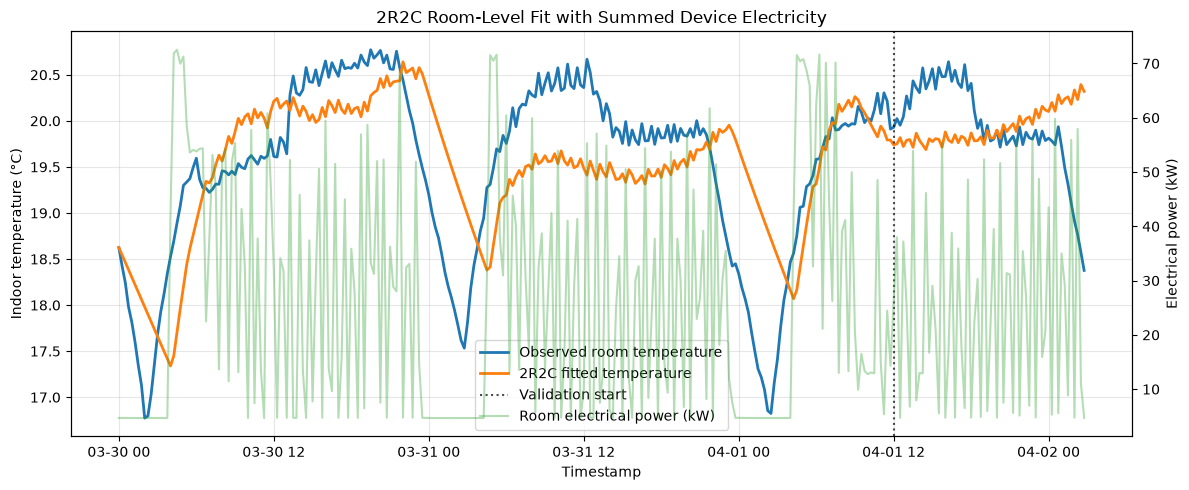

In [4]:
param_table = pd.DataFrame({"parameter": param_names, "value": best_params}).set_index("parameter")
assert (param_table["value"] > 0).all(), "All calibrated 2R2C parameters must be positive."
display(param_table)

T_fit, T_wall_fit = simulate_2r2c_states(best_params, T_in[0], T_wall_init, T_out, Q_heat, dt)
assert np.all(np.isfinite(T_fit)), "Calibrated 2R2C fit must be finite."

rmse_train = float(np.sqrt(np.mean((T_fit[:train_end] - T_in[:train_end]) ** 2)))
rmse_val = float(np.sqrt(np.mean((T_fit[train_end:] - T_in[train_end:]) ** 2)))
rmse_all = float(np.sqrt(np.mean((T_fit - T_in) ** 2)))

metrics_2r2c = pd.DataFrame(
    [
        {"split": "train", "rmse_c": rmse_train},
        {"split": "validation", "rmse_c": rmse_val},
        {"split": "full_window", "rmse_c": rmse_all},
    ]
)
print(f"2R2C train RMSE: {rmse_train:.4f} °C")
print(f"2R2C validation RMSE: {rmse_val:.4f} °C")
print(f"2R2C full-window RMSE: {rmse_all:.4f} °C")
display(metrics_2r2c)

model_df["T_2r2c"] = T_fit
model_df["T_wall_2r2c"] = T_wall_fit

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(model_df.index, T_in, label="Observed room temperature", linewidth=2)
ax1.plot(model_df.index, T_fit, label="2R2C fitted temperature", linewidth=2)
ax1.axvline(
    model_df.index[train_end], color="black", linestyle=":", alpha=0.7, label="Validation start"
)
ax1.set_xlabel("Timestamp")
ax1.set_ylabel("Indoor temperature (°C)")
ax1.grid(True, alpha=0.3)
ax2 = ax1.twinx()
ax2.plot(
    model_df.index, Q_electric, color="tab:green", alpha=0.35, label="Room electrical power (kW)"
)
ax2.set_ylabel("Electrical power (kW)")
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="best")
plt.title("2R2C Room-Level Fit with Summed Device Electricity")
plt.tight_layout()
plt.show()

## Interpretation

Positive `R_in`, `C_in`, `R_out`, and `C_wall` values confirm that the optimizer found a physically admissible 2R2C parameter set. Smaller resistance values imply easier heat transfer across the corresponding boundary; larger capacitance values imply slower temperature movement for the same heat flow.

The model is still deliberately compact. The key correction is that it now uses room-level summed electrical power instead of one device's power. The remaining limitation is that `Q_heat_kw` is an effective heat proxy because COP, compressor cycling, fan state, defrost, solar gains, ventilation, and occupancy heat are not fully measured.

# Section 6: Level-2 Residual Corrector

The second level learns only the residual left by the calibrated physical model:

```text
residual[k] = T_observed[k] - T_2R2C[k]
hybrid_prediction[k] = T_2R2C[k] + residual_corrector(features[k])
```

This is a black-box residual layer after the physical model, not a physics-loss neural model. It receives stateful and operational features that the former absolute-temperature neural model lacked, including previous indoor temperature, previous residual, target/control indicators, current electrical power, current interval electricity spent, and cumulative electricity spent.

In [5]:
class ResidualCorrector(nn.Module):
    """Small MLP that predicts residuals around the calibrated 2R2C baseline."""

    def __init__(self, input_dim, hidden_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, x):
        return self.net(x)

# Section 7: Residual Features

The residual model includes physics baseline state, lagged measured state, lagged model error, control context, and electricity-spend features. In particular, `Q_electric_kw`, `electricity_kwh`, and `cumulative_electricity_kwh` keep current electrical spend visible to the learned correction layer.

In [6]:
residual = T_in - T_fit
model_df["previous_T_in"] = model_df["T_in"].shift(1).fillna(model_df["T_in"].iloc[0])
model_df["previous_residual"] = pd.Series(residual, index=model_df.index).shift(1).fillna(0.0)
model_df["delta_T_out_in"] = model_df["T_out"] - model_df["T_2r2c"]

if "hour_of_day" in model_df.columns:
    model_df["hour_sin"] = np.sin(2 * np.pi * model_df["hour_of_day"] / 24.0)
    model_df["hour_cos"] = np.cos(2 * np.pi * model_df["hour_of_day"] / 24.0)

feature_cols = [
    "T_2r2c",
    "T_wall_2r2c",
    "previous_T_in",
    "previous_residual",
    "delta_T_out_in",
    "T_out",
    "Q_electric_kw",
    "electricity_kwh",
    "cumulative_electricity_kwh",
    "target_temp",
    "occupancy_flag",
    "is_heating_required",
    "status_is_compressor_active",
    "status_is_defrost_active",
    "is_weekend",
    "hour_sin",
    "hour_cos",
]
available_feature_cols = [col for col in feature_cols if col in model_df.columns]
required_energy_features = {"Q_electric_kw", "electricity_kwh", "cumulative_electricity_kwh"}
assert required_energy_features <= set(available_feature_cols), (
    "Electricity features must be present."
)

X = model_df[available_feature_cols].to_numpy(dtype=float)
y = residual.astype(float)
if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
    raise ValueError("Residual feature matrix and target must be finite.")

X_scaler = StandardScaler()
X_train_norm = X_scaler.fit_transform(X[:train_end])
X_val_norm = X_scaler.transform(X[train_end:])
X_all_norm = X_scaler.transform(X)

y_mean = float(y[:train_end].mean())
y_std = float(y[:train_end].std())
if y_std == 0.0:
    y_std = 1.0
y_train_norm = (y[:train_end] - y_mean) / y_std
y_val_norm = (y[train_end:] - y_mean) / y_std

X_train_tensor = torch.tensor(X_train_norm, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_norm, dtype=torch.float32).unsqueeze(1)
X_val_tensor = torch.tensor(X_val_norm, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_norm, dtype=torch.float32).unsqueeze(1)
X_all_tensor = torch.tensor(X_all_norm, dtype=torch.float32)

print("Residual feature columns:")
for col in available_feature_cols:
    print(f"- {col}")

Residual feature columns:
- T_2r2c
- T_wall_2r2c
- previous_T_in
- previous_residual
- delta_T_out_in
- T_out
- Q_electric_kw
- electricity_kwh
- cumulative_electricity_kwh
- target_temp
- occupancy_flag
- is_heating_required
- status_is_compressor_active
- status_is_defrost_active
- is_weekend
- hour_sin
- hour_cos


# Section 8: Residual Corrector Training

The residual corrector is trained with ordinary residual MSE. There is no separate physics loss because the physical constraint is already represented by the level-1 2R2C simulator.

In [7]:
torch.manual_seed(42)
np.random.seed(42)

residual_model = ResidualCorrector(input_dim=X_train_tensor.shape[1], hidden_dim=32)
optimizer = torch.optim.Adam(residual_model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()
epochs = 600

train_loss_history = []
val_loss_history = []

for epoch in range(epochs):
    residual_model.train()
    optimizer.zero_grad()
    train_pred = residual_model(X_train_tensor)
    train_loss = criterion(train_pred, y_train_tensor)
    train_loss.backward()
    optimizer.step()

    residual_model.eval()
    with torch.no_grad():
        val_pred = residual_model(X_val_tensor)
        val_loss = criterion(val_pred, y_val_tensor)

    train_loss_history.append(train_loss.item())
    val_loss_history.append(val_loss.item())

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train residual MSE: {train_loss.item():.4f} | "
            f"Validation residual MSE: {val_loss.item():.4f}"
        )

Epoch 001 | Train residual MSE: 0.9488 | Validation residual MSE: 0.6888
Epoch 100 | Train residual MSE: 0.0604 | Validation residual MSE: 0.0979
Epoch 200 | Train residual MSE: 0.0216 | Validation residual MSE: 0.0799
Epoch 300 | Train residual MSE: 0.0160 | Validation residual MSE: 0.0924
Epoch 400 | Train residual MSE: 0.0135 | Validation residual MSE: 0.0974
Epoch 500 | Train residual MSE: 0.0119 | Validation residual MSE: 0.1121
Epoch 600 | Train residual MSE: 0.0106 | Validation residual MSE: 0.1269


# Section 9: Hybrid Results

The hybrid prediction is the physical 2R2C baseline plus the learned residual correction. Metrics below compare the physical baseline with the corrected prediction on train, validation, and full-window splits.

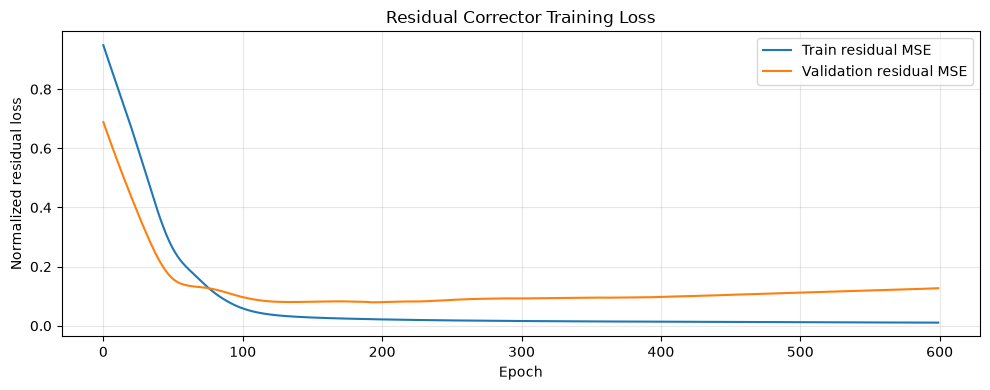

2R2C vs residual-corrected hybrid RMSE:


,split,2r2c_rmse_c,hybrid_rmse_c
0,train,0.739667,0.076047
1,validation,0.640010,0.263536
2,full_window,0.720839,0.136076


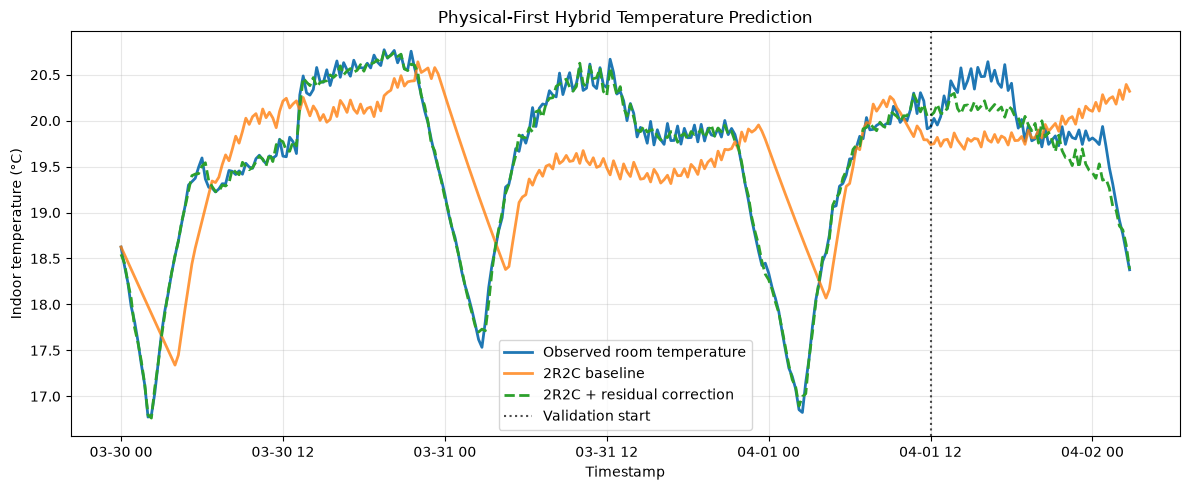

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(train_loss_history, label="Train residual MSE")
plt.plot(val_loss_history, label="Validation residual MSE")
plt.xlabel("Epoch")
plt.ylabel("Normalized residual loss")
plt.title("Residual Corrector Training Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

residual_model.eval()
with torch.no_grad():
    residual_correction = residual_model(X_all_tensor).numpy().flatten() * y_std + y_mean

T_hybrid = T_fit + residual_correction
assert np.all(np.isfinite(T_hybrid)), "Hybrid prediction must be finite."


def rmse(pred, truth):
    return float(np.sqrt(np.mean((pred - truth) ** 2)))


metrics = pd.DataFrame(
    [
        {
            "split": "train",
            "2r2c_rmse_c": rmse(T_fit[:train_end], T_in[:train_end]),
            "hybrid_rmse_c": rmse(T_hybrid[:train_end], T_in[:train_end]),
        },
        {
            "split": "validation",
            "2r2c_rmse_c": rmse(T_fit[train_end:], T_in[train_end:]),
            "hybrid_rmse_c": rmse(T_hybrid[train_end:], T_in[train_end:]),
        },
        {
            "split": "full_window",
            "2r2c_rmse_c": rmse(T_fit, T_in),
            "hybrid_rmse_c": rmse(T_hybrid, T_in),
        },
    ]
)
print("2R2C vs residual-corrected hybrid RMSE:")
display(metrics)

plt.figure(figsize=(12, 5))
plt.plot(model_df.index, T_in, label="Observed room temperature", linewidth=2)
plt.plot(model_df.index, T_fit, label="2R2C baseline", linewidth=2, alpha=0.8)
plt.plot(model_df.index, T_hybrid, label="2R2C + residual correction", linewidth=2, linestyle="--")
plt.axvline(
    model_df.index[train_end], color="black", linestyle=":", alpha=0.7, label="Validation start"
)
plt.xlabel("Timestamp")
plt.ylabel("Indoor temperature (°C)")
plt.title("Physical-First Hybrid Temperature Prediction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Section 10: Electricity Spend Diagnostics

The plot below makes the measured electricity inputs explicit. `Q_electric_kw` is the current summed device power, while `electricity_kwh` is the current interval spend and `cumulative_electricity_kwh` is total spend over the modeled window.

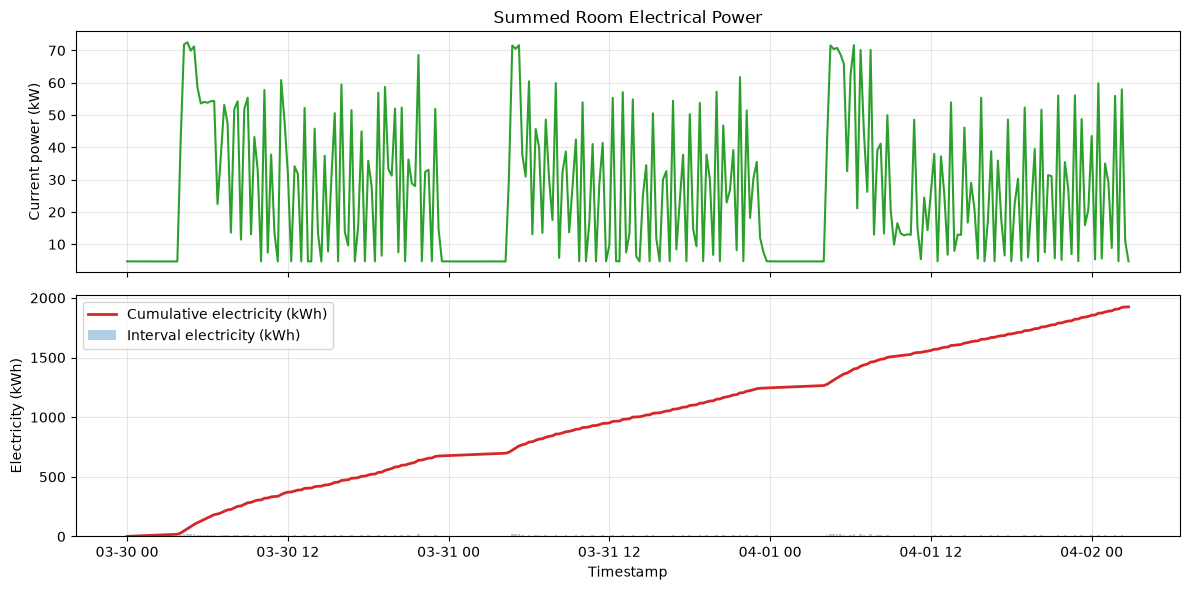

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(model_df.index, model_df["Q_electric_kw"], color="tab:green", linewidth=1.5)
axes[0].set_ylabel("Current power (kW)")
axes[0].set_title("Summed Room Electrical Power")
axes[0].grid(True, alpha=0.3)

axes[1].bar(
    model_df.index,
    model_df["electricity_kwh"],
    width=0.008,
    alpha=0.35,
    label="Interval electricity (kWh)",
)
axes[1].plot(
    model_df.index,
    model_df["cumulative_electricity_kwh"],
    color="tab:red",
    linewidth=2,
    label="Cumulative electricity (kWh)",
)
axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("Electricity (kWh)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2R2C vs Residual Hybrid Comparison

The physical model is now the first layer. The learned model only corrects systematic residuals around that physical trajectory, using lagged state, control context, and measured electricity spend. This ordering avoids asking a neural model to infer hidden thermal mass from time, outdoor temperature, and one device's electrical draw alone.

The result should be interpreted as a grey-box baseline plus empirical correction. If a reliable COP curve or delivered-heat measurement becomes available, `Q_heat_kw` should be updated before recalibrating the 2R2C parameters.

# Section 11: Summary & Forward Look

1. **Room-level inputs:** The model now uses one room-level thermal series and summed electrical power from all devices serving the room.
2. **Electricity spend:** Current power, interval kWh, and cumulative kWh are explicit model features and diagnostics.
3. **2R2C first:** The calibrated physical model remains the primary predictor and retains interpretable positive thermal parameters.
4. **Residual correction second:** The neural layer learns empirical residuals around the physical baseline instead of predicting absolute temperature from under-specified inputs.
5. **Remaining limitation:** Delivered heat is still approximated from electrical power using an assumed COP; equipment-specific COP curves would improve physical fidelity.